 EDA on Engineered Features (32 features — Merged 4-Class)

1. Setup & Paths

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

BASE_DIR     = os.path.abspath(os.path.join(os.getcwd(), '..'))
FEATURES_DIR = os.path.join(BASE_DIR, 'Data', 'Features')
REPORTS_DIR  = os.path.join(BASE_DIR, 'Reports', 'images')
os.makedirs(REPORTS_DIR, exist_ok=True)

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

print(f"FEATURES_DIR : {FEATURES_DIR}")
print(f"REPORTS_DIR  : {REPORTS_DIR}")

FEATURES_DIR : d:\Study Assets\Final Project\PhishingGuard\Data\Features
REPORTS_DIR  : d:\Study Assets\Final Project\PhishingGuard\Reports\images


2. Load Data + Feature Groups

In [2]:
df = pd.read_csv(os.path.join(FEATURES_DIR, 'merged_features.csv'))

print("── Loaded ──")
print(f"  Merged : {df.shape} | Label: {sorted(df['Label'].unique())}")

FEATURE_GROUPS = {
    'Lexical': [
        'url_length', 'domain_length', 'path_length', 'num_dots',
        'domain_hyphens', 'path_hyphens',
        'num_underscores', 'num_slashes', 'num_at', 'num_question_marks',
        'num_equals', 'num_ampersands', 'num_percent', 'num_digits',
        'digit_ratio', 'letter_ratio', 'url_entropy', 'domain_entropy',
        'num_subdomains', 'has_ip_address'
    ],
    'Structural': [
        'is_suspicious_tld', 'has_port', 'path_depth',   # đã bỏ has_https
        'num_query_params', 'has_fragment', 'is_shortened_url', 'has_suspicious_word'
    ],
    'Statistical': [
        'consonant_ratio', 'vowel_ratio', 'longest_token_length',
        'avg_token_length', 'special_char_ratio'
    ]
}

ALL_FEATURES = sum(FEATURE_GROUPS.values(), [])
print(f"\nTotal features: {len(ALL_FEATURES)}")
for g, feats in FEATURE_GROUPS.items():
    print(f"  {g:12s}: {len(feats)} features")

── Loaded ──
  Merged : (607458, 34) | Label: ['benign', 'defacement', 'malware', 'phishing']

Total features: 32
  Lexical     : 20 features
  Structural  : 7 features
  Statistical : 5 features


3. Class Distribution

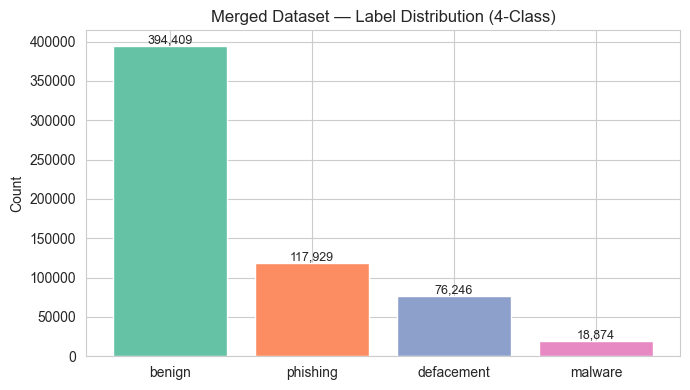


Merged: {'benign': np.int64(394409), 'phishing': np.int64(117929), 'defacement': np.int64(76246), 'malware': np.int64(18874)}


In [3]:
fig, ax = plt.subplots(figsize=(7, 4))

vc = df['Label'].value_counts()
ax.bar(vc.index, vc.values, color=sns.color_palette('Set2'))
ax.set_title('Merged Dataset — Label Distribution (4-Class)')
ax.set_ylabel('Count')
for i, v in enumerate(vc.values):
    ax.text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, 'eda_features_class_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f"\nMerged: {dict(vc)}")

4. Class Means Table

In [4]:
def class_means(df, label_col, features):
    return df.groupby(label_col)[features].mean().round(3)

print("── Merged Dataset: Mean feature values per class ──")
means = class_means(df, 'Label', ALL_FEATURES)
print(means.T.to_string())

── Merged Dataset: Mean feature values per class ──
Label                 benign  defacement  malware  phishing
url_length            66.978      83.265   46.551    55.324
domain_length         16.431      16.200   14.923    20.765
path_length           32.553      23.168   20.389    20.132
num_dots               1.931       2.142    3.023     2.149
domain_hyphens         0.110       0.216    0.147     0.319
path_hyphens           1.686       1.042    0.183     0.220
num_underscores        0.505       0.547    0.127     0.154
num_slashes            4.610       3.838    3.757     3.956
num_at                 0.001       0.000    0.001     0.009
num_question_marks     0.195       0.565    0.058     0.110
num_equals             0.395       2.299    0.168     0.251
num_ampersands         0.203       1.709    0.109     0.143
num_percent            0.669       0.039    0.661     0.066
num_digits             6.412       4.564   11.078     4.968
digit_ratio            0.069       0.045    0.26

5. Boxplots by Feature Group (Merged)

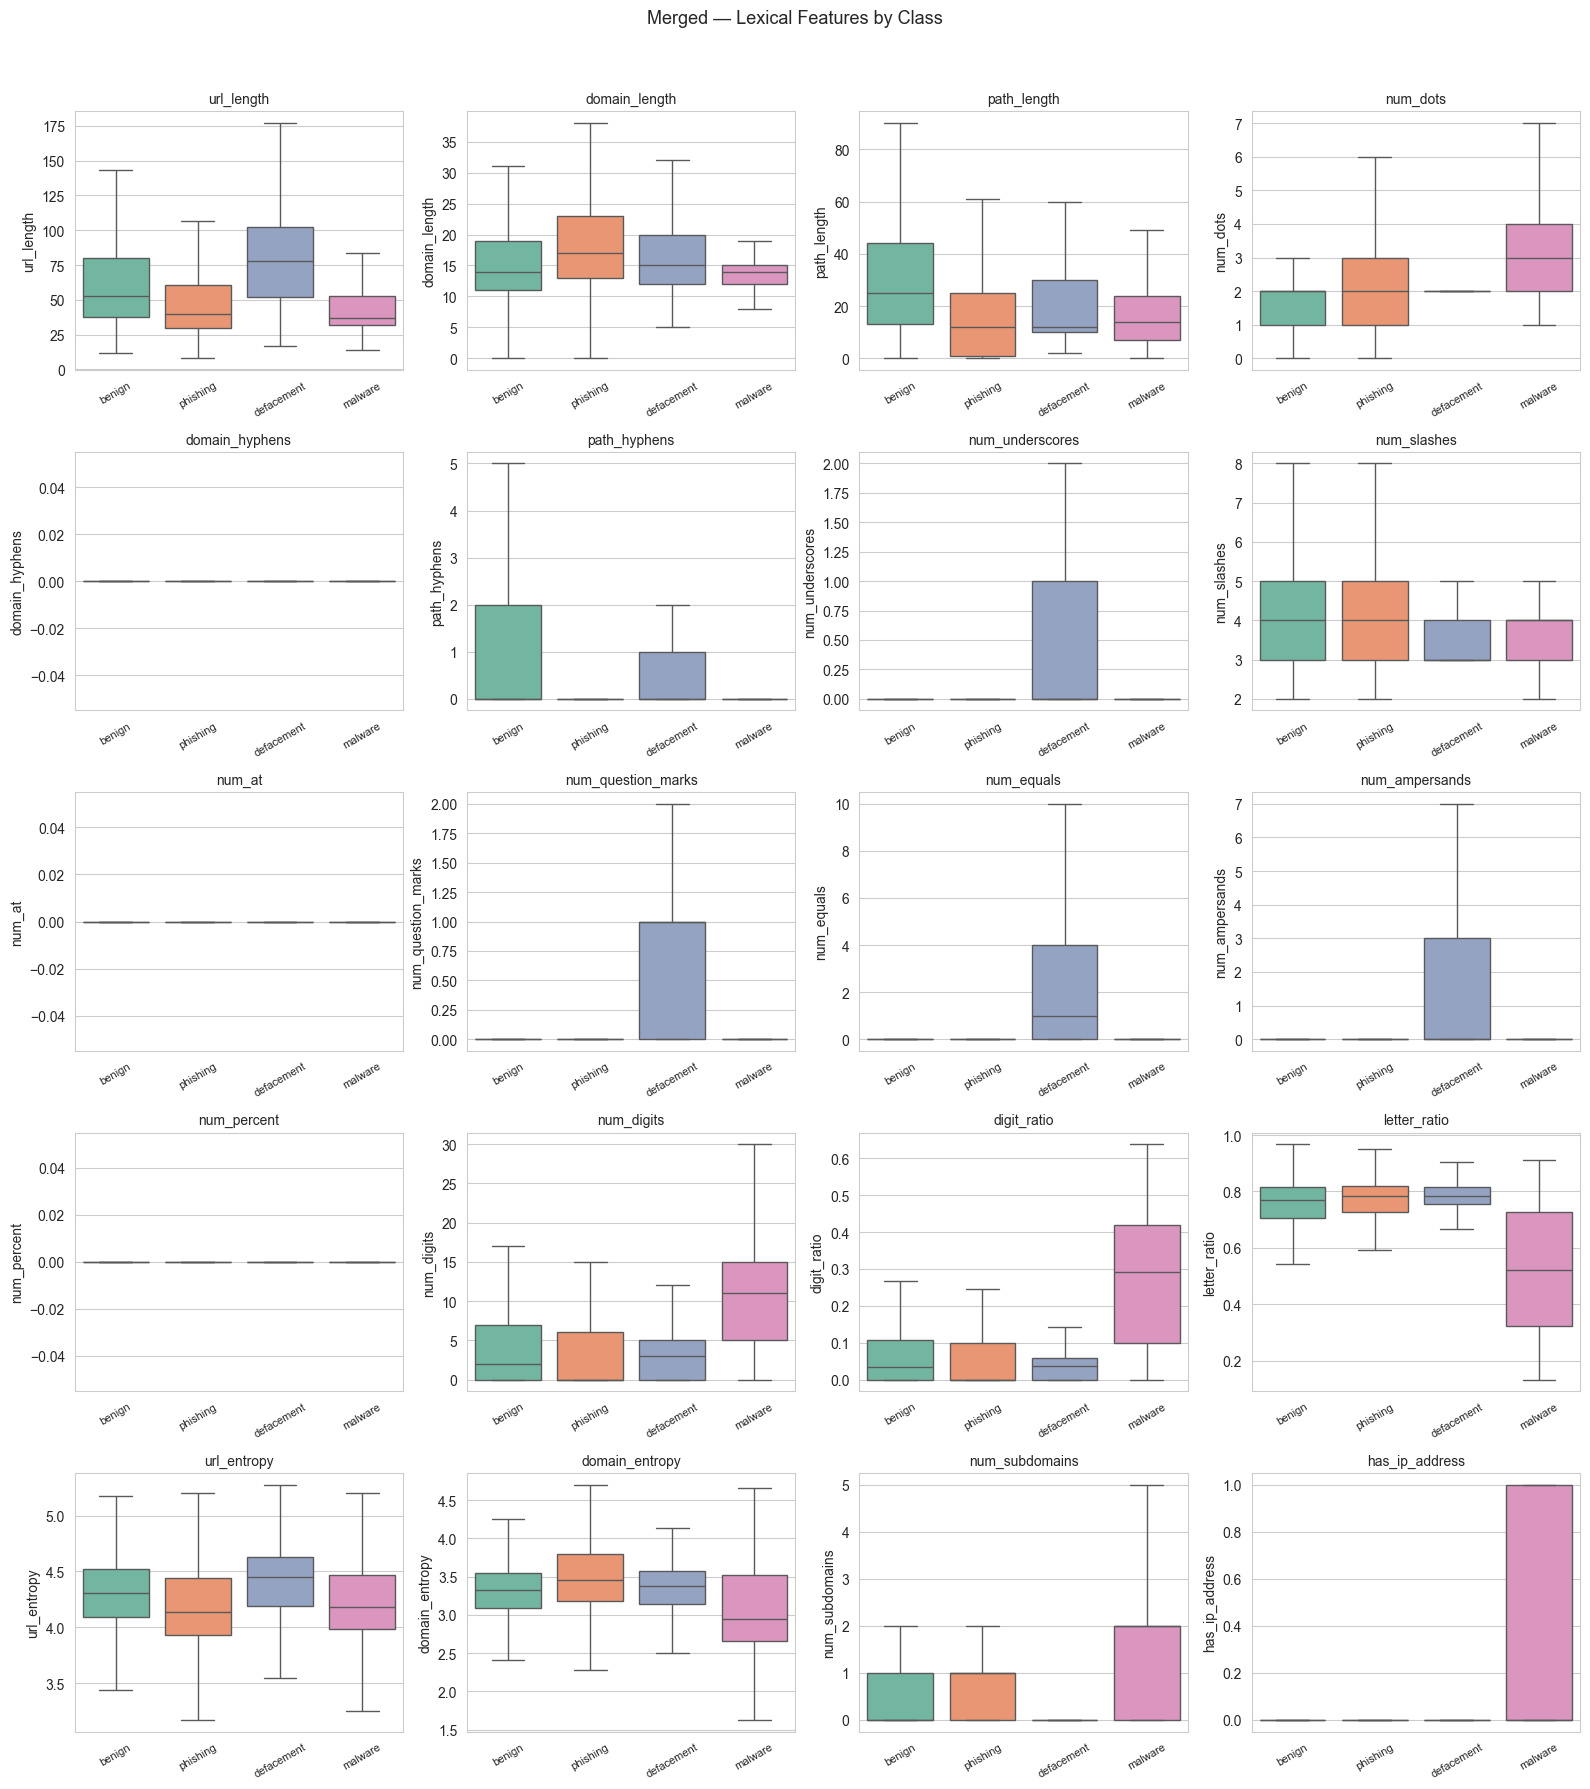

Saved → eda_features_merged_lexical_boxplot.png


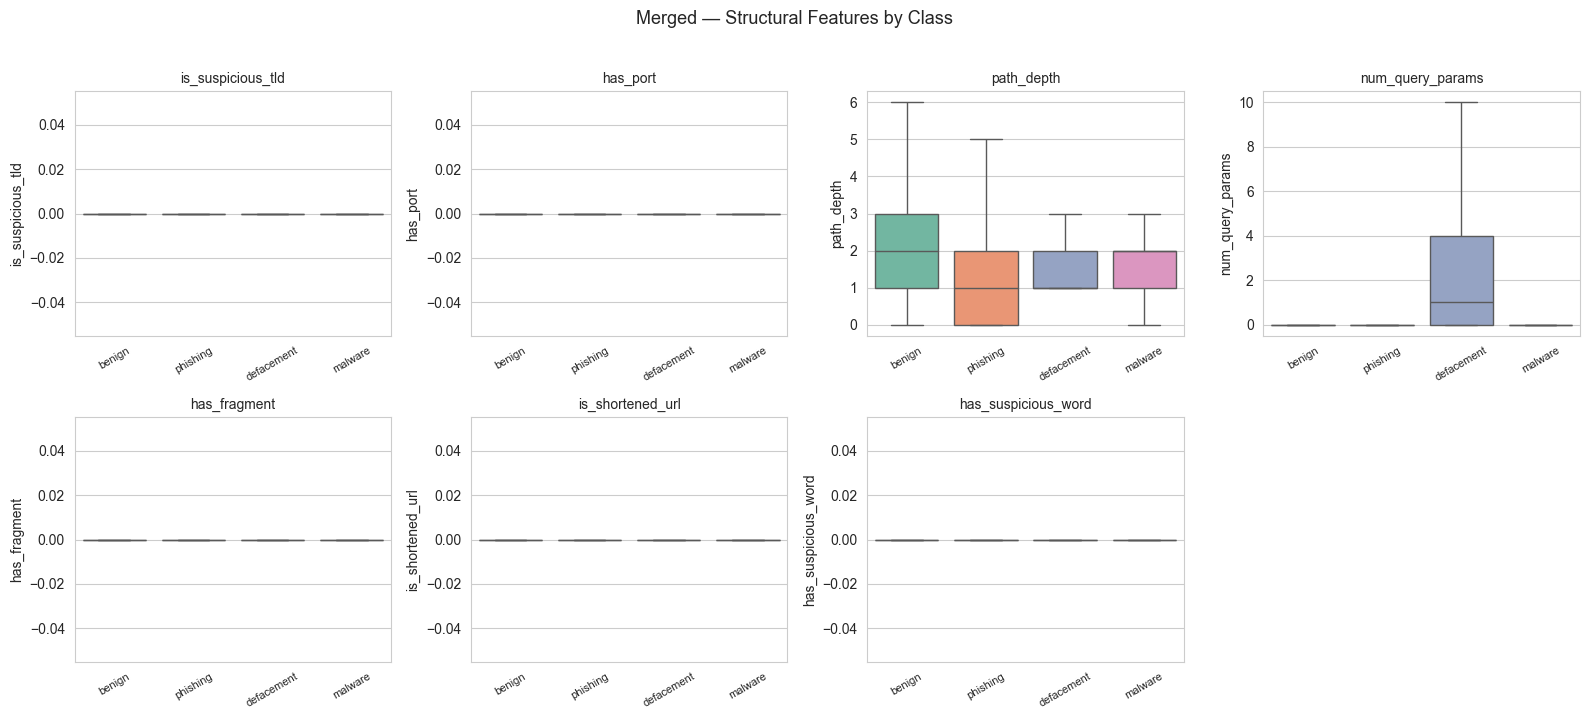

Saved → eda_features_merged_structural_boxplot.png


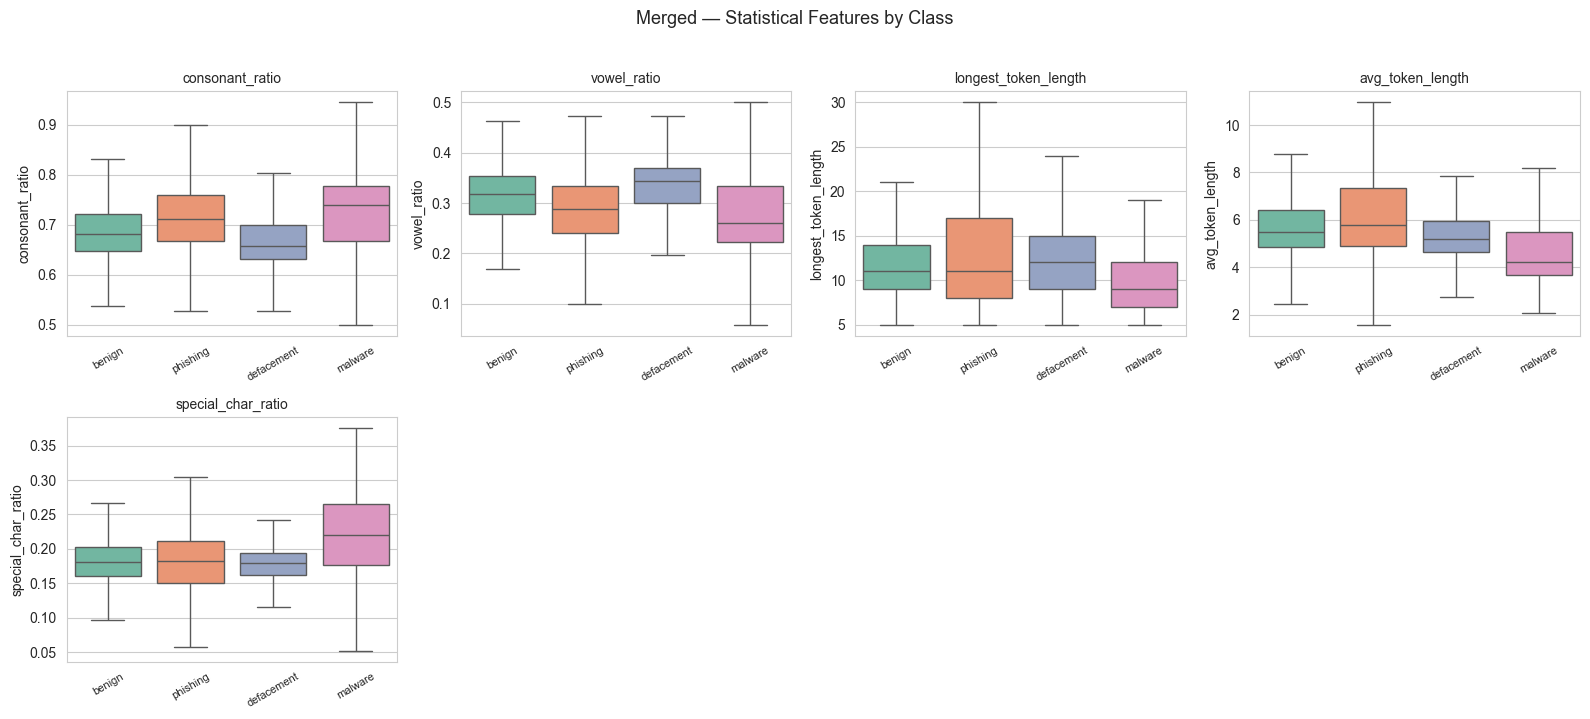

Saved → eda_features_merged_statistical_boxplot.png


In [5]:
def plot_group_boxplots(df, label_col, group_name, features, dataset_name, label_order=None):
    n = len(features)
    cols = 4
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols*4, rows*3.5))
    axes = axes.flatten()

    order = label_order if label_order else sorted(df[label_col].unique())

    for i, feat in enumerate(features):
        sns.boxplot(data=df, x=label_col, y=feat, ax=axes[i], order=order,
                    palette='Set2', showfliers=False)
        axes[i].set_title(feat, fontsize=10)
        axes[i].set_xlabel('')
        axes[i].tick_params(axis='x', rotation=30, labelsize=8)

    for j in range(n, len(axes)):
        axes[j].axis('off')

    fig.suptitle(f'{dataset_name} — {group_name} Features by Class', fontsize=13, y=1.02)
    plt.tight_layout()
    fname = f"eda_features_{dataset_name.lower().replace(' ', '')}_{group_name.lower()}_boxplot.png"
    plt.savefig(os.path.join(REPORTS_DIR, fname), dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved → {fname}")

label_order = ['benign', 'phishing', 'defacement', 'malware']

for group_name, feats in FEATURE_GROUPS.items():
    plot_group_boxplots(df, 'Label', group_name, feats, 'Merged', label_order)

6. Boxplots Dataset 2

7. Correlation Heatmap + High Correlation Pairs

── Merged Dataset ──


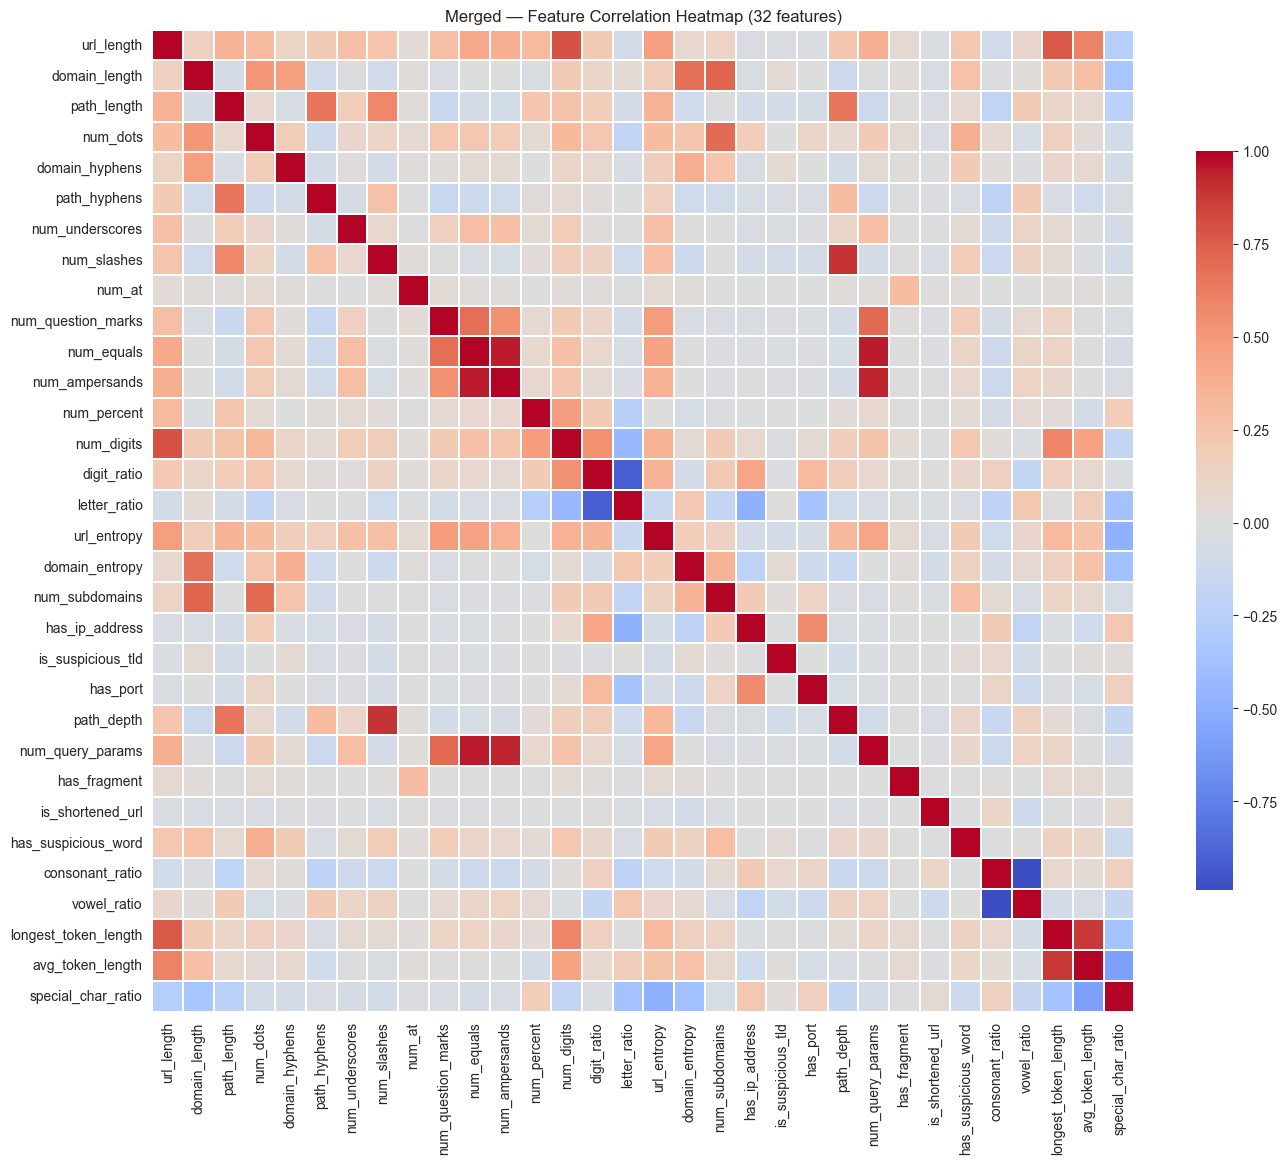

Saved → eda_features_merged_correlation.png

Highly correlated feature pairs (|corr| > 0.8):
           Feature 1        Feature 2  Correlation
          num_equals num_query_params     0.952228
          num_equals   num_ampersands     0.949360
      num_ampersands num_query_params     0.936898
         num_slashes       path_depth     0.898184
longest_token_length avg_token_length     0.877795
         digit_ratio     letter_ratio    -0.916540
     consonant_ratio      vowel_ratio    -0.988918


In [6]:
def plot_correlation_heatmap(df, features, dataset_name):
    corr = df[features].corr()
    plt.figure(figsize=(14, 12))
    sns.heatmap(corr, cmap='coolwarm', center=0, annot=False,
                square=True, linewidths=0.3, cbar_kws={'shrink': 0.7})
    plt.title(f'{dataset_name} — Feature Correlation Heatmap ({len(features)} features)')
    plt.tight_layout()
    fname = f"eda_features_{dataset_name.lower().replace(' ', '')}_correlation.png"
    plt.savefig(os.path.join(REPORTS_DIR, fname), dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved → {fname}")

    high_corr = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    high_corr = high_corr.stack().reset_index()
    high_corr.columns = ['Feature 1', 'Feature 2', 'Correlation']
    high_corr = high_corr[high_corr['Correlation'].abs() > 0.8].sort_values('Correlation', ascending=False)

    print(f"\nHighly correlated feature pairs (|corr| > 0.8):")
    print(high_corr.to_string(index=False) if len(high_corr) > 0 else "  None")
    return high_corr

print("── Merged Dataset ──")
high_corr = plot_correlation_heatmap(df, ALL_FEATURES, 'Merged')

7. Scatterplots for High-Correlation Pairs

── Merged Dataset ──


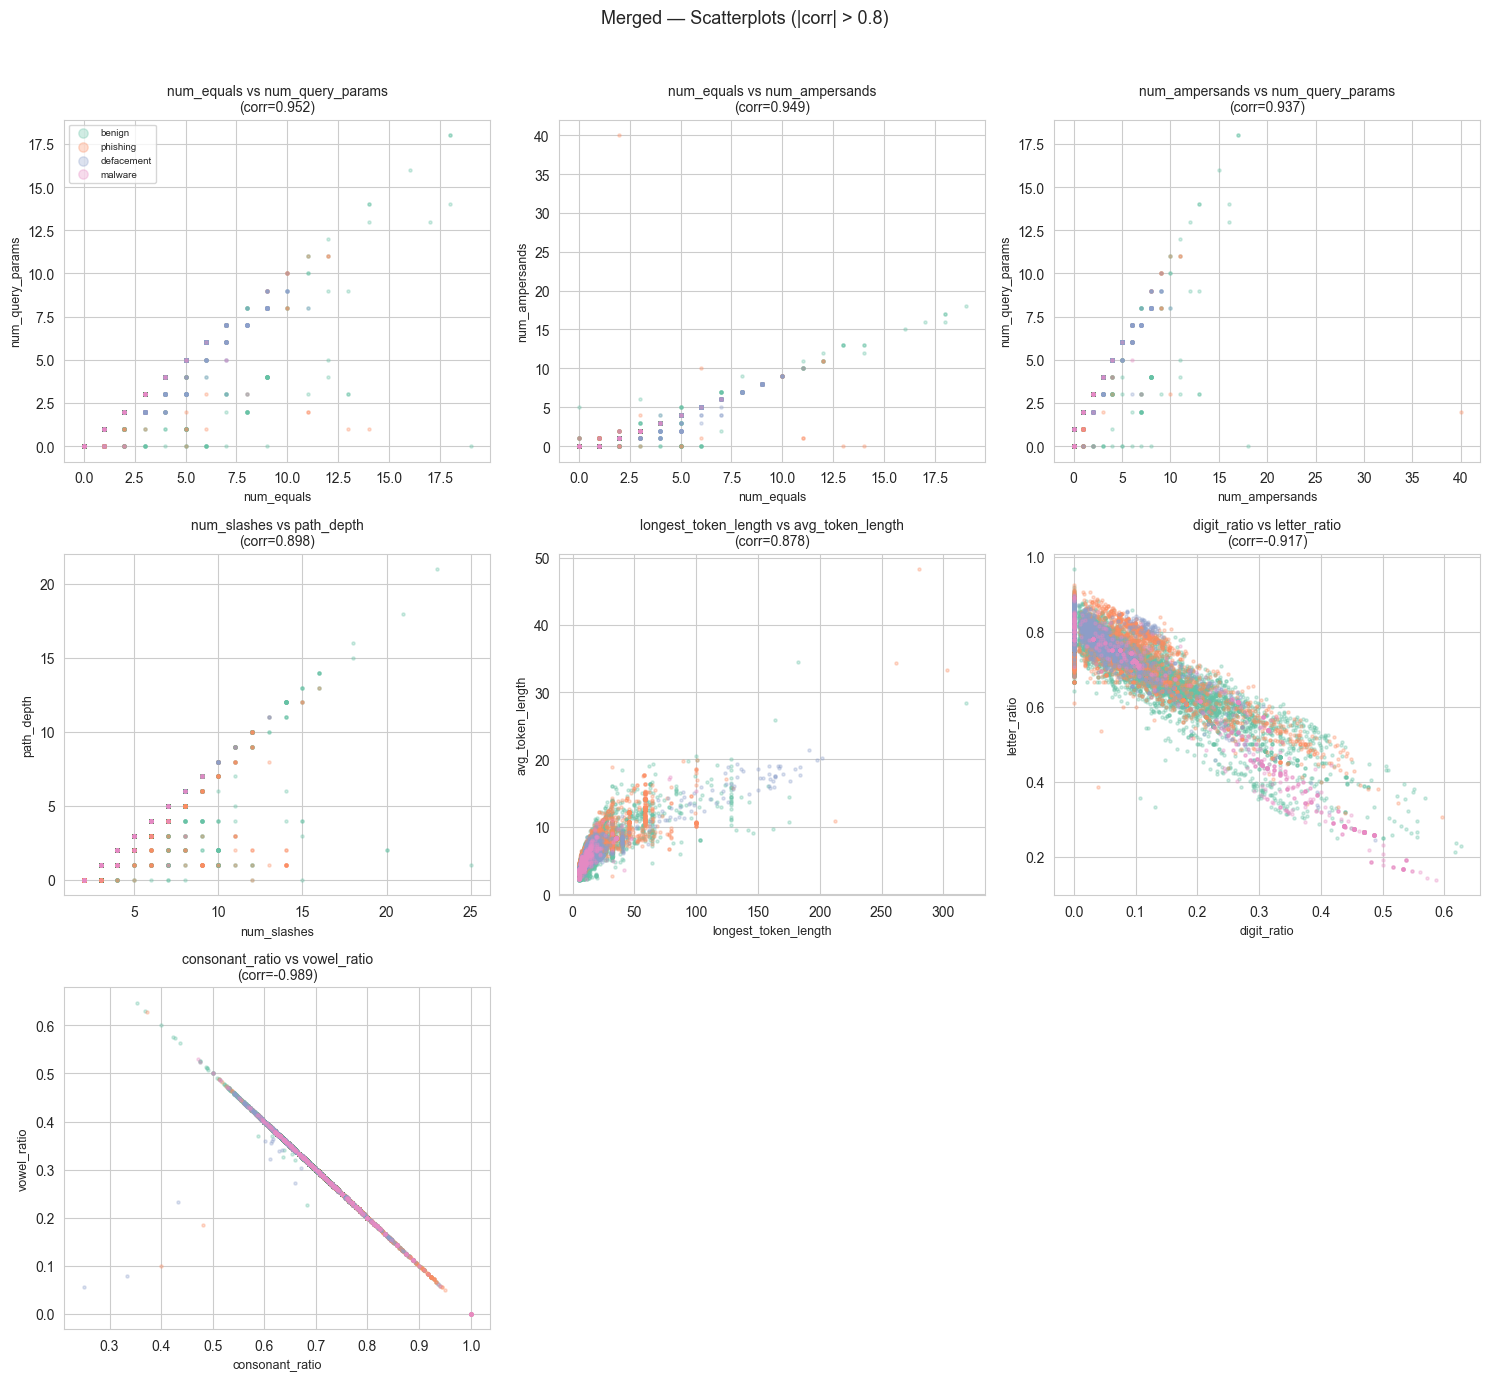

Saved → eda_features_merged_scatterplot.png


In [7]:
def plot_scatter_pairs(df, label_col, high_corr_df, dataset_name, label_order=None, sample_size=20000):
    if len(high_corr_df) == 0:
        print(f"[{dataset_name}] No feature pairs with |corr| > 0.8")
        return

    # Sample để vẽ nhanh hơn — scatterplot với 500K+ điểm sẽ rất chậm
    df_sample = df.sample(n=min(sample_size, len(df)), random_state=42)

    pairs = list(zip(high_corr_df['Feature 1'], high_corr_df['Feature 2']))
    n = len(pairs)
    cols = 3
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols*5, rows*4.5))
    axes = np.array(axes).flatten() if n > 1 else [axes]

    order = label_order if label_order else sorted(df[label_col].unique())
    palette = sns.color_palette('Set2', len(order))

    for i, (f1, f2) in enumerate(pairs):
        for j, label in enumerate(order):
            subset = df_sample[df_sample[label_col] == label]
            axes[i].scatter(subset[f1], subset[f2], s=5, alpha=0.3,
                           color=palette[j], label=label)
        corr_val = high_corr_df.iloc[i]['Correlation']
        axes[i].set_xlabel(f1, fontsize=9)
        axes[i].set_ylabel(f2, fontsize=9)
        axes[i].set_title(f'{f1} vs {f2}\n(corr={corr_val:.3f})', fontsize=10)
        if i == 0:
            axes[i].legend(fontsize=7, markerscale=3)

    for j in range(n, len(axes)):
        axes[j].axis('off')

    fig.suptitle(f'{dataset_name} — Scatterplots (|corr| > 0.8)', fontsize=13, y=1.02)
    plt.tight_layout()
    fname = f"eda_features_{dataset_name.lower().replace(' ', '')}_scatterplot.png"
    plt.savefig(os.path.join(REPORTS_DIR, fname), dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved → {fname}")

print("── Merged Dataset ──")
plot_scatter_pairs(df, 'Label', high_corr, 'Merged', label_order)

9. Mutual Information Ranking

── Merged: Top 15 features by Mutual Information ──
           Feature  Mutual Info
       path_length     0.209897
    domain_entropy     0.171188
       digit_ratio     0.144434
      letter_ratio     0.136962
special_char_ratio     0.131503
  avg_token_length     0.130418
       url_entropy     0.106694
   consonant_ratio     0.097564
       vowel_ratio     0.094676
        num_equals     0.091479
  num_query_params     0.090371
    num_ampersands     0.084323
       num_slashes     0.083013
        path_depth     0.079117
        url_length     0.076295


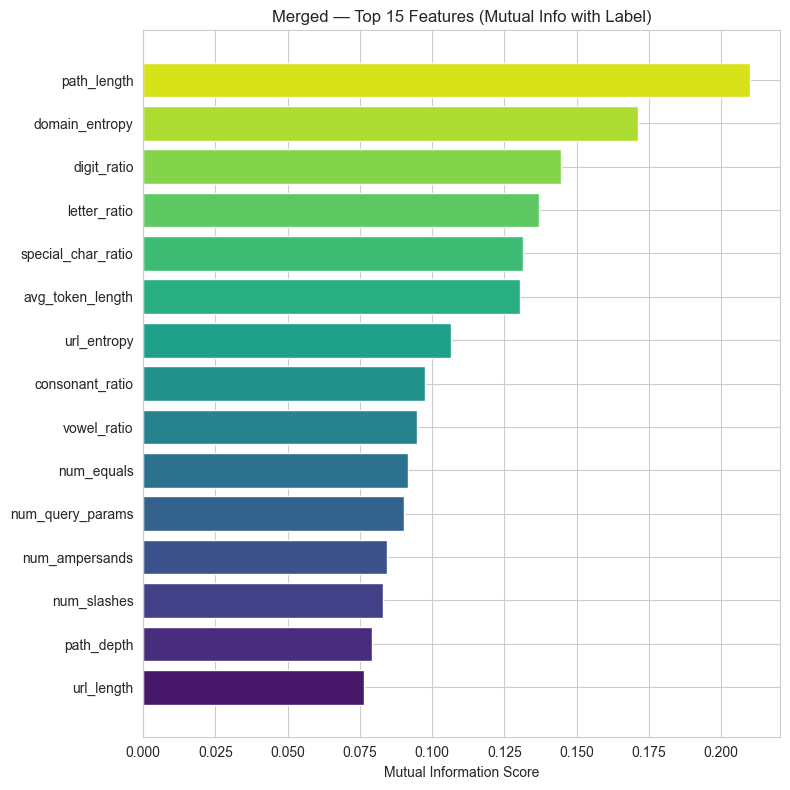

Saved → eda_features_merged_mutual_info.png


: 

In [ ]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder

def mutual_info_ranking(df, label_col, features, dataset_name, sample_size=50000):
    # Sample để tính nhanh hơn — MI ranking không cần full dataset
    df_sample = df.sample(n=min(sample_size, len(df)), random_state=42) if len(df) > sample_size else df

    X = df_sample[features].values
    if df_sample[label_col].dtype == object:
        le = LabelEncoder()
        y = le.fit_transform(df_sample[label_col])
    else:
        y = df_sample[label_col].values

    mi = mutual_info_classif(X, y, random_state=42, n_neighbors=3)
    mi_df = pd.DataFrame({'Feature': features, 'Mutual Info': mi})
    mi_df = mi_df.sort_values('Mutual Info', ascending=False).reset_index(drop=True)

    print(f"── {dataset_name}: Top 15 features by Mutual Information ──")
    print(mi_df.head(15).to_string(index=False))

    plt.figure(figsize=(8, 8))
    top15 = mi_df.head(15)
    plt.barh(top15['Feature'][::-1], top15['Mutual Info'][::-1],
             color=sns.color_palette('viridis', 15))
    plt.xlabel('Mutual Information Score')
    plt.title(f'{dataset_name} — Top 15 Features (Mutual Info with Label)')
    plt.tight_layout()
    fname = f"eda_features_{dataset_name.lower().replace(' ', '')}_mutual_info.png"
    plt.savefig(os.path.join(REPORTS_DIR, fname), dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved → {fname}")
    return mi_df

mi_merged = mutual_info_ranking(df, 'Label', ALL_FEATURES, 'Merged')